# DSS301 – Data Science for Smart Agriculture
## Mid-Term Project — Chili (*Red Sky 86 F1*) — Pursat Site

### Growth-stage prediction, weather-driven yield loss & daily yield (0–150 DAT)

**Group 5** — Khon Sotheara · Khann Udomvirak · Chea Sela · Cheang Youpheng

**Mid-term requirements covered**
1. Download hourly weather data (air temperature & humidity, rainwater, soil temperature, soil moisture) from 0 DAT until the end of harvesting
2. Calculate GDD for the chili plant
3. Prediction model for the exact date of each growth stage (10 stages of the QC data collection guidelines)
4. Yield loss due to weather
5. Daily attainable yield from the 1st harvesting date until the end of the season, by plantation area
6. Apply the **teacher-supplied soil laboratory analysis** (`DSSA.pdf`, Lab ID 11/23) to the two field blocks

**Season & constants** — planting (0 DAT) **04/07/2026** · end of harvesting **02/12/2026** · 1 block = 0.5 ha · 1 ha = 25,000 plants

**Site** — **Pursat, Cambodia — 12.1409° N, 104.0849° E** (Damnak Trayeung village, Phnum Kravanh district), the location supplied by the course instructor on the map link in `Links.md`. NASA POWER elevation for the grid cell: **121.88 m**.

**Data source** — NASA POWER Data Access Viewer / API (hourly, Single-Point, AG community) — the same source listed by the instructor.

**Headline results (Pursat 2026)** — season GDD **2,621** (base 10 °C) · stages **+1 to +2 days** against the standard calendar · weather yield loss **−32.2 %** · attained **1.05 kg/plant ≈ 26,280 kg/ha** · season total **1,485 t** (56.5 ha) or **907 t** (34.5 ha) · soils are **silt loam with pH ≈ 7.1**, above the 5.0–6.5 chili optimum.

## 1. Site selection — why the analysis was moved to Pursat

The earlier version of this project screened ten Cambodian provinces and selected **Kampot** because no farm location had been given. The instructor has since supplied a **specific field location** on the map link in `Links.md`:

`12°08'27.2"N 104°05'05.5"E` → **12.140874, 104.0848521**

Reverse geocoding resolves this to **Damnak Trayeung village, Phnum Kravanh district, Pursat province** — the foothills west of the Tonle Sap, roughly 250 km north-west of the Kampot site. Because the brief asks for predictions *for the farm*, every result below is computed for this coordinate.

This is consistent with the original screening, where Pursat scored **0.755** against Kampot's 0.758 — effectively a tie on climate, and now decided by the actual field location rather than by a screening score.

**Why the move is defensible on the numbers:** Pursat is cooler (mean 26.8 °C vs 27.4 °C), receives 36 % less rain (900 mm vs 1,402 mm), and has a drier root zone (mean wetness 0.70 vs 0.85) — a materially different water balance from the Kampot analysis. Simply relabelling the Kampot run would have been wrong.

## 2. Weather dataset (NASA POWER, hourly)

All parameters required by the brief, for every hour of the day from 0 DAT to the end of harvesting: air temperature at two levels (**T2M**, **T10M**), humidity (**RH2M** relative, **QV2M / QV10M** specific), rainwater (**PRECTOTCORR**), soil temperature in six layers (**TSOIL1–6**) and soil wetness (**GWETTOP / GWETROOT / GWETPROF**).

**3,648 rows = 152 days × 24 hours**, no missing values in any parameter.

**Availability note:** MERRA-2 latency means the 2026 record ends **12/10/2026**. Rows from 13/10/2026 to 02/12/2026 use the *same calendar dates of 2025* as a **labelled proxy** (`source` = `actual_2026` vs `proxy_2025`). This is a data-quality limitation and is quantified in Section 7.

In [1]:
import os, csv, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "."
LAT, LON = 12.1409, 104.0849          # instructor-supplied field location (Pursat)
SITE = "Pursat"
START = pd.Timestamp("2026-07-04")    # 0 DAT
BASE_T = 10.0                         # GDD base temperature for chili (C)

print("folder:", os.path.abspath(BASE))
print("site:", SITE, "(lat, lon) =", (LAT, LON))

folder: /media/theara/184E41A94E41810C/Theara/YEAR 3/SEMESTER 1/DSSA/Chili Midterm
site: Pursat (lat, lon) = (12.1409, 104.0849)


In [2]:
def power_csv(params, start, end, temporal="hourly"):
    url = (f"https://power.larc.nasa.gov/api/temporal/{temporal}/point?"
           f"parameters={params}&community=AG&longitude={LON}&latitude={LAT}"
           f"&start={start}&end={end}&format=CSV")
    with urllib.request.urlopen(url, timeout=120) as r:
        text = r.read().decode()
    lines = text.splitlines()
    elev = None
    for l in lines:
        if l.lower().startswith("elevation"):
            hit = re.search(r"([-\d.]+)\s*meters", l)
            elev = hit.group(1) if hit else None
    hi = next(i for i, l in enumerate(lines) if l.startswith("YEAR,"))
    return lines[hi].split(","), list(csv.reader(lines[hi + 1:])), elev


def build_hourly():
    path = os.path.join(BASE, f"{SITE}_weather_hourly_2026_season.csv")
    if os.path.exists(path):
        d = pd.read_csv(path)
        d["date"] = pd.to_datetime(d["date"])
        print("loaded cached dataset:", path)
        return d
    params = ("T2M,T10M,RH2M,QV2M,QV10M,PRECTOTCORR,"
              "TSOIL1,TSOIL2,TSOIL3,TSOIL4,TSOIL5,TSOIL6,"
              "GWETTOP,GWETROOT,GWETPROF")
    rename = {"T2M": "T2M_C", "T10M": "T10M_C", "RH2M": "RH2M_pct",
              "QV2M": "QV2M_gkg", "QV10M": "QV10M_gkg",
              "PRECTOTCORR": "PRECTOTCORR_mm", "GWETTOP": "GWETTOP_frac",
              "GWETROOT": "GWETROOT_frac", "GWETPROF": "GWETPROF_frac", "HR": "hour"}
    for i in range(1, 7):
        rename[f"TSOIL{i}"] = f"TSOIL{i}_C"
    parts = []
    for src, s, e in [("actual_2026", "20260704", "20261012"),
                      ("proxy_2025", "20251013", "20251202")]:
        hdr, rows, elev = power_csv(params, s, e)
        d = pd.DataFrame(rows, columns=hdr)
        for c in hdr:
            d[c] = pd.to_numeric(d[c], errors="coerce")
        keep = [c for c in hdr if c in rename]
        d[keep] = d[keep].replace(-999.0, np.nan)      # NASA fill value -> NaN
        d["source"] = src
        d["elevation_m"] = float(elev) if elev else np.nan
        dt = d[["YEAR", "MO", "DY"]].astype(int)
        d["actual_datetime"] = (dt["YEAR"].astype(str) + "-" +
                                dt["MO"].astype(str).str.zfill(2) + "-" +
                                dt["DY"].astype(str).str.zfill(2) + " " +
                                d["HR"].astype(int).astype(str).str.zfill(2) + ":00")
        d["date"] = pd.to_datetime(pd.DataFrame(
            {"year": 2026, "month": dt["MO"], "day": dt["DY"]}))
        d["DAT"] = (d["date"] - START).dt.days
        parts.append(d)
    out = pd.concat(parts, ignore_index=True).rename(columns=rename)
    out = out[["DAT", "date", "hour", "source", "actual_datetime", "elevation_m"] +
              [rename[c] for c in hdr[4:]]]
    out.to_csv(path, index=False)
    print("downloaded from NASA POWER and saved:", path)
    return out


df = build_hourly()
print(df.shape)
df.head(3)

loaded cached dataset: ./Pursat_weather_hourly_2026_season.csv
(3648, 21)


,DAT,date,hour,source,actual_datetime,elevation_m,T2M_C,T10M_C,RH2M_pct,QV2M_gkg,...,PRECTOTCORR_mm,TSOIL1_C,TSOIL2_C,TSOIL3_C,TSOIL4_C,TSOIL5_C,TSOIL6_C,GWETTOP_frac,GWETROOT_frac,GWETPROF_frac
0,0,2026-07-04,0,actual_2026,2026-07-04 00:00,121.88,25.20,25.37,95.66,19.42,...,0.20,26.79,28.80,29.71,30.19,30.2,28.3,0.56,0.55,0.54
1,0,2026-07-04,1,actual_2026,2026-07-04 01:00,121.88,25.05,25.23,95.93,19.31,...,0.27,26.61,28.73,29.70,30.19,30.2,28.3,0.56,0.55,0.54
2,0,2026-07-04,2,actual_2026,2026-07-04 02:00,121.88,24.91,25.10,96.10,19.19,...,0.37,26.44,28.65,29.69,30.19,30.2,28.3,0.56,0.55,0.54


In [3]:
params = [c for c in df.columns if c not in
          ("DAT", "date", "hour", "source", "actual_datetime", "elevation_m")]
print("rows:", len(df), "| columns:", len(df.columns))
print(df.groupby("source")[["date"]].agg(["min", "max", "count"]).to_string())
print("missing values (NaN):", int(df[params].isna().sum().sum()))
df[params].describe().round(2)

rows: 3648 | columns: 21
                  date                 
                   min        max count
source                                 
actual_2026 2026-07-04 2026-10-12  2424
proxy_2025  2026-10-13 2026-12-02  1224
missing values (NaN): 0


,T2M_C,T10M_C,RH2M_pct,QV2M_gkg,QV10M_gkg,PRECTOTCORR_mm,TSOIL1_C,TSOIL2_C,TSOIL3_C,TSOIL4_C,TSOIL5_C,TSOIL6_C,GWETTOP_frac,GWETROOT_frac,GWETPROF_frac
count,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00,3648.00
mean,26.84,26.95,83.68,18.50,17.97,0.25,26.99,27.21,27.62,28.26,28.92,28.20,0.71,0.70,0.68
std,2.93,2.68,12.88,1.65,1.65,0.47,2.09,1.17,1.00,0.93,0.82,0.34,0.08,0.06,0.06
min,15.59,15.86,42.90,9.45,8.93,0.00,18.85,23.06,25.11,26.55,27.18,27.05,0.53,0.55,0.54
25%,24.70,24.99,73.51,18.14,17.62,0.01,25.62,26.53,26.93,27.38,28.34,28.23,0.65,0.65,0.63
50%,26.22,26.50,88.68,18.82,18.37,0.09,26.74,27.39,27.90,28.40,28.96,28.32,0.71,0.70,0.67
75%,29.08,29.01,94.61,19.41,18.89,0.28,28.40,28.04,28.32,28.91,29.60,28.36,0.78,0.76,0.73
max,35.42,34.65,100.00,22.36,21.18,6.46,33.93,30.14,29.71,30.19,30.20,28.38,0.96,0.83,0.79


## 3. Growing Degree Days (GDD)

Daily GDD from the hourly temperatures with base temperature **10 °C** (standard for chili/pepper):

**GDD_day = max(0, (Tmax + Tmin) / 2 − 10)**  and  **GDD_cum(t) = Σ GDD_day**

Season total **2,621 GDD** (mean 17.2/day). The three reference seasons at the same location accumulated **2,655** (2023), **2,681** (2024) and **2,662** (2025) GDD, mean **2,666** — so 2026 is about **-46 GDD** against the local normal, i.e. a slightly *cooler* season than usual.

In [4]:
daily = (df.groupby("date")
           .agg(Tmax_C=("T2M_C", "max"), Tmin_C=("T2M_C", "min"),
                Tmean_C=("T2M_C", "mean"), rain_mm=("PRECTOTCORR_mm", "sum"),
                n_valid=("T2M_C", "count"), source=("source", "first"))
           .reset_index())
daily["DAT"] = (daily["date"] - START).dt.days
daily["GDD_day"] = np.maximum(0.0, (daily["Tmax_C"] + daily["Tmin_C"]) / 2.0 - BASE_T)
daily["GDD_cum"] = daily["GDD_day"].cumsum()

print(f"days: {len(daily)} | total GDD: {daily['GDD_cum'].iloc[-1]:,.0f} "
      f"| mean daily GDD: {daily['GDD_day'].mean():.1f}")
cols = ["DAT", "date", "source", "Tmax_C", "Tmin_C", "Tmean_C", "GDD_day", "GDD_cum"]
daily[cols].to_csv(os.path.join(BASE, f"{SITE}_GDD_daily_2026.csv"), index=False)
daily[cols].tail(3)

days: 152 | total GDD: 2,621 | mean daily GDD: 17.2


,DAT,date,source,Tmax_C,Tmin_C,Tmean_C,GDD_day,GDD_cum
149,149,2026-11-30,proxy_2025,31.7,18.75,24.967917,15.225,2587.605
150,150,2026-12-01,proxy_2025,32.5,20.63,26.185833,16.565,2604.170
151,151,2026-12-02,proxy_2025,30.7,22.11,26.610833,16.405,2620.575


## 4. Soil & microclimate conditions (all brief parameters used)

The brief also asks for soil temperature, soil moisture and the humidity/elevation profiles. Measured over 04/07 – 02/12 at the Pursat point:

| Check | Result | Interpretation |
|---|---|---|
| Soil temp, surface TSOIL1 (0–10 cm) | 27.0 / 33.9 °C (mean / max) | no surface heat stress (0 h above 35 °C) |
| Soil temp, root zone TSOIL2 (10–40 cm) | 27.2 / 30.1 °C | very stable, near-ideal for root growth |
| Root-zone wetness GWETROOT | mean / min 0.70 / 0.55 | never water-limited; 0 h below 0.3 |
| Surface wetness GWETTOP | mean 0.71; 482 / 5 h above 0.8 / 0.9 | moderate waterlogging risk, far lower than Kampot |
| Air temperature gradient T2M vs T10M | mean -0.114 °C | uniform, stably stratified air |
| Humidity gradient QV2M vs QV10M | 0.530 g/kg | moisture concentrated near the canopy |

**Interpretation:** the root zone stays between 0.55 and near-saturation all season, so this site is **not drought-limited** either — but unlike Kampot it also never becomes waterlogged for long stretches. The dominant agronomic risk here is **humidity-driven disease**, which is exactly what the loss model in Section 7 measures.

In [5]:
soil = pd.DataFrame({
    "check": ["TSOIL1 surface (0-10 cm) mean / max (C)",
              "TSOIL2 root zone (10-40 cm) mean / max (C)",
              "hours TSOIL1 > 35 C",
              "GWETROOT (root zone) mean / min",
              "hours GWETROOT > 0.8",
              "hours GWETROOT < 0.3 (water stress)",
              "GWETTOP surface mean",
              "hours GWETTOP > 0.8 / > 0.9",
              "T2M - T10M mean diff (C)",
              "QV2M - QV10M mean diff (g/kg)"],
    "value": [f"{df['TSOIL1_C'].mean():.1f} / {df['TSOIL1_C'].max():.1f}",
              f"{df['TSOIL2_C'].mean():.1f} / {df['TSOIL2_C'].max():.1f}",
              int((df["TSOIL1_C"] > 35).sum()),
              f"{df['GWETROOT_frac'].mean():.2f} / {df['GWETROOT_frac'].min():.2f}",
              int((df["GWETROOT_frac"] > 0.8).sum()),
              int((df["GWETROOT_frac"] < 0.3).sum()),
              f"{df['GWETTOP_frac'].mean():.2f}",
              f"{int((df['GWETTOP_frac'] > 0.8).sum())} / {int((df['GWETTOP_frac'] > 0.9).sum())}",
              f"{(df['T2M_C'] - df['T10M_C']).mean():.3f}",
              f"{(df['QV2M_gkg'] - df['QV10M_gkg']).mean():.3f}"]})
soil

,check,value
0,TSOIL1 surface (0-10 cm) mean / max (C),27.0 / 33.9
1,TSOIL2 root zone (10-40 cm) mean / max (C),27.2 / 30.1
2,hours TSOIL1 > 35 C,0
3,GWETROOT (root zone) mean / min,0.70 / 0.55
4,hours GWETROOT > 0.8,158
5,hours GWETROOT < 0.3 (water stress),0
6,GWETTOP surface mean,0.71
7,hours GWETTOP > 0.8 / > 0.9,482 / 5
8,T2M - T10M mean diff (C),-0.114
9,QV2M - QV10M mean diff (g/kg),0.530


## 5. Stage prediction model

**Logic:** every growth stage needs a fixed amount of thermal time. Thresholds are calibrated from **three reference seasons of Pursat climate (2023–2025)** — the cumulative GDD the farm-standard DAT calendar normally accumulates — then applied to the **actual 2026 weather** to predict the exact date each stage is reached, and compared with the standard calendar (anchors 7 / 30 / 45 / 60 / 75 / 150 DAT).

| Stage | DAT anchor | GDD threshold | Standard date | Predicted date | Δ days |
|---|---:|---:|---|---|---:|
| 1. Transplant | 0 | – | 04/07/2026 | 04/07/2026 | 0 |
| 2. Establishment | 7 | 151 | 11/07/2026 | 12/07/2026 | +1 |
| 3. Vegetative | 30 | 579 | 03/08/2026 | 04/08/2026 | +1 |
| 4. Flowering | 45 | 860 | 18/08/2026 | 20/08/2026 | +2 |
| 5. Fruit set | 60 | 1,127 | 02/09/2026 | 04/09/2026 | +2 |
| 6. First harvest | 75 | 1,387 | 17/09/2026 | 18/09/2026 | +1 |
| 10. End of cycle | 150 | 2,649 | 02/12/2026 | 04/12/2026 | +2 |

Every stage arrives **1–2 days later** than the standard calendar: 2026 is marginally cooler than the three reference seasons, so the crop needs a little longer to accumulate the same thermal time.

**One honest caveat:** the end-of-cycle threshold (**2,649 GDD**) lies *beyond* the downloaded window (2026 reaches 2,621 GDD), so that single date is **extrapolated** at the late-season rate rather than observed. The code flags it with an `extrapolated` column instead of hiding it.

In [6]:
ref_path = os.path.join(BASE, f"{SITE}_reference_GDD_2023-2025.csv")
if os.path.exists(ref_path):
    ref = pd.read_csv(ref_path)
    ref["date"] = pd.to_datetime(ref["date"])
    print("loaded cached reference:", ref_path)
else:
    frames = []
    for y in (2023, 2024, 2025):
        hdr, rows, _ = power_csv("T2M_MAX,T2M_MIN", f"{y}0704", f"{y}1202", temporal="daily")
        d = pd.DataFrame(rows, columns=hdr)
        for c in hdr:
            d[c] = pd.to_numeric(d[c], errors="coerce").replace(-999.0, np.nan)
        d["date"] = pd.to_datetime(d["YEAR"].astype(int).astype(str) + "-" +
                                   d["DOY"].astype(int).astype(str).str.zfill(3), format="%Y-%j")
        d["DAT"] = (d["date"] - pd.to_datetime(str(y) + "-07-04")).dt.days
        d["GDD_day"] = np.maximum(0.0, (d["T2M_MAX"] + d["T2M_MIN"]) / 2.0 - BASE_T)
        d["GDD_cum"] = d["GDD_day"].cumsum()
        d = d.rename(columns={"YEAR": "year", "T2M_MAX": "Tmax_C", "T2M_MIN": "Tmin_C"})
        frames.append(d[["year", "date", "DAT", "Tmax_C", "Tmin_C", "GDD_day", "GDD_cum"]])
    ref = pd.concat(frames, ignore_index=True)
    ref.to_csv(ref_path, index=False)
    print("downloaded reference seasons and saved:", ref_path)

ref = ref.sort_values(["year", "DAT"])
ref["GDD_day"] = np.maximum(0.0, (ref["Tmax_C"] + ref["Tmin_C"]) / 2.0 - BASE_T)
ref["GDD_cum"] = ref.groupby("year")["GDD_day"].cumsum()

anchors = [("Establishment", 7), ("Vegetative", 30), ("Flowering", 45),
           ("Fruit set", 60), ("First harvest", 75), ("End of cycle", 150)]
th = {}
for name, a in anchors:
    vals = [ref[(ref["year"] == y) & (ref["DAT"] == a)]["GDD_cum"].iloc[0]
            for y in sorted(ref["year"].unique())
            if len(ref[(ref["year"] == y) & (ref["DAT"] == a)]) > 0]
    th[name] = float(np.mean(vals))

print("reference season totals:", ref.groupby("year")["GDD_cum"].max().round(0).to_dict())
pd.DataFrame({"anchor_DAT": pd.Series(dict(anchors)),
              "threshold_GDD": pd.Series(th).round(0)})

loaded cached reference: ./Pursat_reference_GDD_2023-2025.csv
reference season totals: {2023: 2655.0, 2024: 2681.0, 2025: 2662.0}


,anchor_DAT,threshold_GDD
Establishment,7,151.0
Vegetative,30,579.0
Flowering,45,860.0
Fruit set,60,1127.0
First harvest,75,1387.0
End of cycle,150,2649.0


In [7]:
std_date = {n: START + pd.Timedelta(days=a) for n, a in anchors}
# the farm calendar fixes the end of harvesting at 02/12/2026 (DAT 151), so the last
# stage is compared against that date rather than the raw DAT-150 offset (01/12)
std_date["End of cycle"] = pd.Timestamp("2026-12-02")


def crossing(t):
    """First day cumulative GDD reaches t. If the threshold lies beyond the
    downloaded window, extrapolate at the last-14-day rate and flag it."""
    hit = daily[daily["GDD_cum"] >= t]
    if len(hit):
        return hit.iloc[0], False
    last = daily.iloc[-1]
    rate = daily["GDD_day"].tail(14).mean()
    new_date = (last["date"] + pd.Timedelta(days=(t - last["GDD_cum"]) / rate)).ceil("D")
    row = last.copy()
    row["date"] = new_date
    row["DAT"] = int((new_date - START).days)
    return row, True


pred, extrap = {}, {}
for n, v in th.items():
    pred[n], extrap[n] = crossing(v)

rows = []
for name, a in anchors:
    p = pred[name]
    rows.append({"stage": name, "anchor_DAT": a,
                 "standard_date": std_date[name].strftime("%d/%m/%Y"),
                 "threshold_GDD": round(th[name]),
                 "predicted_date": p["date"].strftime("%d/%m/%Y"),
                 "predicted_DAT": int(p["DAT"]),
                 "delta_days": int((p["date"] - std_date[name]).days),
                 "extrapolated": extrap[name]})
pd.DataFrame(rows)

,stage,anchor_DAT,standard_date,threshold_GDD,predicted_date,predicted_DAT,delta_days,extrapolated
0,Establishment,7,11/07/2026,151,12/07/2026,8,1,False
1,Vegetative,30,03/08/2026,579,04/08/2026,31,1,False
2,Flowering,45,18/08/2026,860,20/08/2026,47,2,False
3,Fruit set,60,02/09/2026,1127,04/09/2026,62,2,False
4,First harvest,75,17/09/2026,1387,18/09/2026,76,1,False
5,End of cycle,150,02/12/2026,2649,04/12/2026,153,2,True


In [8]:
fh = pred["First harvest"]["date"]; eoc = pred["End of cycle"]["date"]
fh_d = fh.strftime("%d/%m/%Y"); eoc_d = eoc.strftime("%d/%m/%Y")


def prow(stage, anchor, std, tname, note=""):
    p = pred[tname]
    return [stage, anchor, std, round(th[tname]), p["date"].strftime("%d/%m/%Y"),
            int(p["DAT"]), int((p["date"] - std_date[tname]).days), note]


table10 = [
    ["1. Transplant", 0, "04/07/2026", 0, "04/07/2026", 0, 0, "fixed planting date"],
    prow("2. Establishment", 7, "11/07/2026", "Establishment"),
    prow("3. Vegetative", 30, "03/08/2026", "Vegetative"),
    prow("4. Flowering", 45, "18/08/2026", "Flowering"),
    prow("5. Fruit set", 60, "02/09/2026", "Fruit set"),
    prow("6. First harvest", 75, "17/09/2026", "First harvest"),
    prow("7. Market fruit", 75, "17/09/2026", "First harvest", "same DAT anchor as first harvest"),
    ["8. Maturity", "75+", "starts 17/09/2026", "", fh_d, int(pred["First harvest"]["DAT"]), "",
     "colour change within harvest window"],
    ["9. Harvest", "75-150", "17/09/2026-02/12/2026", "", f"{fh_d} to {eoc_d}", "", "",
     "window from first harvest to end of cycle"],
    ["10. End of cycle", 150, "02/12/2026", round(th["End of cycle"]), eoc_d,
     int(pred["End of cycle"]["DAT"]), int((eoc - std_date["End of cycle"]).days), ""],
]
cols10 = ["stage", "DAT_anchor", "standard_date", "GDD_threshold", "predicted_date",
          "predicted_DAT", "delta_days", "note"]
table10 = pd.DataFrame(table10, columns=cols10).convert_dtypes()
table10.to_csv(os.path.join(BASE, f"{SITE}_stage_predictions.csv"), index=False)
table10

,stage,DAT_anchor,standard_date,GDD_threshold,predicted_date,predicted_DAT,delta_days,note
0,1. Transplant,0,04/07/2026,0,04/07/2026,0,0,fixed planting date
1,2. Establishment,7,11/07/2026,151,12/07/2026,8,1,
2,3. Vegetative,30,03/08/2026,579,04/08/2026,31,1,
3,4. Flowering,45,18/08/2026,860,20/08/2026,47,2,
4,5. Fruit set,60,02/09/2026,1127,04/09/2026,62,2,
5,6. First harvest,75,17/09/2026,1387,18/09/2026,76,1,
6,7. Market fruit,75,17/09/2026,1387,18/09/2026,76,1,same DAT anchor as first harvest
7,8. Maturity,75+,starts 17/09/2026,,18/09/2026,76,,colour change within harvest window
8,9. Harvest,75-150,17/09/2026-02/12/2026,,18/09/2026 to 04/12/2026,,,window from first harvest to end of cycle
9,10. End of cycle,150,02/12/2026,2649,04/12/2026,153,2,


**Model robustness:** the base temperature (10 °C for chili) is a modelling choice, not a measured value. Re-calibrating the thresholds *and* re-predicting 2026 with 8 °C and 12 °C gives essentially the same stage dates — the prediction does not depend on this choice.

In [9]:
sens_rows = []
for bt in (8.0, 10.0, 12.0):
    gdd_bt = np.maximum(0.0, (daily["Tmax_C"] + daily["Tmin_C"]) / 2.0 - bt)
    cum26 = gdd_bt.cumsum()
    row = {"base_T_C": bt, "season_GDD": round(cum26.iloc[-1])}
    for name, a in anchors:
        per_year = []
        for y, g in ref.groupby("year"):
            g = g.sort_values("DAT")
            cum = np.maximum(0.0, (g["Tmax_C"] + g["Tmin_C"]) / 2.0 - bt).cumsum()
            per_year.append(cum[g["DAT"] == a].iloc[0])
        tgt = float(np.mean(per_year))
        hit = daily[cum26 >= tgt]
        if len(hit):
            row[name] = hit["date"].iloc[0].strftime("%d/%m")
        else:
            extra_d = (tgt - cum26.iloc[-1]) / gdd_bt.tail(14).mean()
            row[name] = (daily["date"].iloc[-1] +
                         pd.Timedelta(days=extra_d)).ceil("D").strftime("%d/%m")
    sens_rows.append(row)
pd.DataFrame(sens_rows).set_index("base_T_C")

,season_GDD,Establishment,Vegetative,Flowering,Fruit set,First harvest,End of cycle
base_T_C,,,,,,,
8.0,2925,12/07,04/08,20/08,04/09,18/09,04/12
10.0,2621,12/07,04/08,20/08,04/09,18/09,04/12
12.0,2317,12/07,04/08,20/08,04/09,19/09,05/12


## 6. Yield loss due to weather

Potential yield for Red Sky 86 F1 per the supplier planting guide: **1.5–1.6 kg/plant** (mid value **1.55** used). A transparent stress-index model applies documented penalties for weather stress during the sensitive phase (flowering → harvest, 45–150 DAT):

| Stressor | Window | Penalty assumption |
|---|---|---|
| hours > 35 °C | 45–150 DAT | 0.20 % per hour |
| hours 32–35 °C | 45–150 DAT | 0.05 % per hour |
| warm nights (Tmin > 24 °C) | 45–75 DAT | 0.30 % per night |
| hours RH ≥ 90 % (disease pressure) | 45–150 DAT | 0.02 % per hour |
| days > 50 mm rain | 45–150 DAT | 0.50 % per day |
| dry-spell days beyond 7 | 40–90 DAT | 0.30 % per day |

Total loss is capped at 35 %. The same coefficients as the Kampot analysis are used, so the two sites are directly comparable.

| Stressor | Count at Pursat | Penalty | Loss |
|---|---:|---:|---:|
| hours >35C | 0 | 0.20 % | −0.00 % |
| hours 32-35C | 64 | 0.05 % | −3.20 % |
| warm nights >24C | 16 | 0.30 % | −4.80 % |
| hours RH>=90% | 1,209 | 0.02 % | −24.18 % |
| days >50mm rain | 0 | 0.50 % | −0.00 % |
| dry-spell days beyond 7 | 0 | 0.30 % | −0.00 % |

**Total weather loss: −32.18 %** → attained yield **1.051 kg/plant**.

In [10]:
w1 = (45, 75)
season = (45, 150)
win = df[(df["DAT"] >= season[0]) & (df["DAT"] <= season[1])]
dstats = df.groupby("date").agg(Tmin_C=("T2M_C", "min"),
                                rain_mm=("PRECTOTCORR_mm", "sum")).reset_index()
dstats["DAT"] = (dstats["date"] - START).dt.days

h35 = int((win["T2M_C"] > 35).sum())
h32 = int(((win["T2M_C"] > 32) & (win["T2M_C"] <= 35)).sum())
warm = int(((dstats["Tmin_C"] > 24) & dstats["DAT"].between(*w1)).sum())
rh90 = int((win["RH2M_pct"] >= 90).sum())
heavy = int(((dstats["rain_mm"] > 50) & dstats["DAT"].between(*season)).sum())

run = extra = 0
for r in dstats.sort_values("DAT").itertuples():
    if 40 <= r.DAT <= 90:
        if r.rain_mm < 1.0:
            run += 1
        else:
            if run > 7:
                extra += run - 7
            run = 0
if run > 7:
    extra += run - 7

coef = {"hours >35C": (h35, 0.20), "hours 32-35C": (h32, 0.05),
        "warm nights >24C": (warm, 0.30), "hours RH>=90%": (rh90, 0.02),
        "days >50mm rain": (heavy, 0.50), "dry-spell days beyond 7": (extra, 0.30)}
loss_tbl = pd.DataFrame([{"stressor": k, "count": c, "penalty_%/unit": w, "loss_%": c * w}
                         for k, (c, w) in coef.items()])
loss = min(35.0, loss_tbl["loss_%"].sum())
print(loss_tbl.to_string(index=False))
print(f"TOTAL LOSS: -{loss:.2f}% (cap 35%) "
      f"-> achieved yield: {1.55 * (1 - loss / 100):.3f} kg/plant")

               stressor  count  penalty_%/unit  loss_%
             hours >35C      0            0.20    0.00
           hours 32-35C     64            0.05    3.20
       warm nights >24C     16            0.30    4.80
          hours RH>=90%   1209            0.02   24.18
        days >50mm rain      0            0.50    0.00
dry-spell days beyond 7      0            0.30    0.00
TOTAL LOSS: -32.18% (cap 35%) -> achieved yield: 1.051 kg/plant


**Where the loss comes from — and how much rests on the proxy.** The disease-pressure channel dominates: **1,209 hours with RH ≥ 90 %** versus 878 at Kampot, despite a lower mean humidity. Of those hours, **686 are actual 2026 observations** and **523** come from the labelled 2025 proxy window, so **10.46 of the 32.18 percentage points** (≈ 33 %) depend on the proxy — the remaining **21.72** points are driven by real 2026 weather. No heat above 35 °C occurred inside the 45–150 DAT window, no day exceeded 50 mm, and no dry spell ran past 7 days.

In [11]:
src_by_date = df.groupby("date")["source"].first()
dd = dstats.assign(source=dstats["date"].map(src_by_date))
rh_src = win.groupby("source")["RH2M_pct"].apply(lambda s: int((s >= 90).sum()))
wn_src = dd[(dd["Tmin_C"] > 24) & dd["DAT"].between(*w1)].groupby("source").size()
hr_src = dd[(dd["rain_mm"] > 50) & dd["DAT"].between(*season)].groupby("source").size()
loss_proxy = 0.02 * int(rh_src.get("proxy_2025", 0))
print("Source transparency (share of the loss resting on the 2025 proxy):")
print("  RH>=90 hours :", {k: int(v) for k, v in rh_src.items()})
print("  warm nights  :", {k: int(v) for k, v in wn_src.items()})
print("  heavy rain days:", {k: int(v) for k, v in hr_src.items()})
print(f"  -> proxy-driven loss = {loss_proxy:.2f}% of the {loss:.2f}% total "
      f"({loss_proxy / loss * 100:.0f}%); the other {loss - loss_proxy:.2f}% "
      f"is driven by actual 2026 weather")

Source transparency (share of the loss resting on the 2025 proxy):
  RH>=90 hours : {'actual_2026': 686, 'proxy_2025': 523}
  warm nights  : {'actual_2026': 16}
  heavy rain days: {}
  -> proxy-driven loss = 10.46% of the 32.18% total (33%); the other 21.72% is driven by actual 2026 weather


## 7. Daily attainable yield (1st harvest → end of season)

Attainable yield = plants × achieved kg/plant, distributed over the harvest window (**18/09/2026 → 04/12/2026**) with a smooth bell-shaped picking curve peaking mid-season — the same distribution used for the Kampot analysis, so the two sites can be compared directly.

**Area options from the brief data:** 113 blocks (A1-A66 + B1-B47) = **56.5 ha**, or 69 planted plots = **34.5 ha**; density **25,000 plants/ha** as fixed by the brief. Pursat: **26,280 kg/ha**, season totals **1,484.8 t** and **906.7 t**; daily peak **680 kg/ha/day** on 26 Oct 2026.

In [12]:
POT_YIELD = 1.55
PLANTS_PER_HA = 25000
achieved = POT_YIELD * (1 - loss / 100)
per_ha_total = PLANTS_PER_HA * achieved

days = pd.date_range(fh, eoc, freq="D")
center = (len(days) - 1) / 2
sigma = len(days) / 5
w = np.exp(-((np.arange(len(days)) - center) ** 2) / (2 * sigma ** 2))
w = w / w.sum()

area_options = {"113 blocks (A1-A66 + B1-B47)": 113 * 0.5,
                "69 planted plots": 69 * 0.5}
ydf = pd.DataFrame({"date": days})
ydf["DAT"] = (ydf["date"] - START).dt.days
ydf["kg_per_ha"] = per_ha_total * w
for name, ha in area_options.items():
    ydf[f"kg_total[{name}]"] = ydf["kg_per_ha"] * ha
    ydf[f"cum_total[{name}]"] = ydf[f"kg_total[{name}]"].cumsum()
ydf.to_csv(os.path.join(BASE, f"{SITE}_daily_yield.csv"), index=False)

print(f"season yield: {per_ha_total:,.0f} kg/ha | achieved {achieved:.3f} kg/plant")
for name, ha in area_options.items():
    tot = ydf[f"kg_total[{name}]"].sum()
    print(f"{name:30s} {ha:5.1f} ha | {ha * PLANTS_PER_HA:,.0f} plants | "
          f"{tot / 1000:,.1f} t | avg {tot / len(ydf):,.0f} kg/day")
ydf.head()

season yield: 26,280 kg/ha | achieved 1.051 kg/plant
113 blocks (A1-A66 + B1-B47)    56.5 ha | 1,412,500 plants | 1,484.8 t | avg 19,036 kg/day
69 planted plots                34.5 ha | 862,500 plants | 906.7 t | avg 11,624 kg/day


,date,DAT,kg_per_ha,kg_total[113 blocks (A1-A66 + B1-B47)],cum_total[113 blocks (A1-A66 + B1-B47)],kg_total[69 planted plots],cum_total[69 planted plots]
0,2026-09-18,76,32.377379,1829.321928,1829.321928,1117.019584,1117.019584
1,2026-09-19,77,37.849103,2138.474316,3967.796244,1305.794052,2422.813636
2,2026-09-20,78,44.064101,2489.621700,6457.417944,1520.211481,3943.025116
3,2026-09-21,79,51.089265,2886.543499,9343.961444,1762.579659,5705.604775
4,2026-09-22,80,58.991553,3333.022736,12676.984179,2035.208573,7740.813348


In [13]:
scen = {}
for label, mult in [("optimistic (0.5x penalties)", 0.5), ("central", 1.0),
                    ("pessimistic (1.5x penalties)", 1.5)]:
    l = min(35.0, mult * sum(c * ww for c, ww in coef.values()))
    ach = POT_YIELD * (1 - l / 100)
    scen[label] = {"loss_%": round(l, 2), "kg_per_plant": round(ach, 3),
                   "kg_per_ha": round(PLANTS_PER_HA * ach),
                   "t (56.5 ha)": round(PLANTS_PER_HA * ach * 56.5 / 1000),
                   "t (34.5 ha)": round(PLANTS_PER_HA * ach * 34.5 / 1000)}
print("Sensitivity of the result to the loss coefficients (+-50%):")
pd.DataFrame(scen).T

Sensitivity of the result to the loss coefficients (+-50%):


,loss_%,kg_per_plant,kg_per_ha,t (56.5 ha),t (34.5 ha)
optimistic (0.5x penalties),16.09,1.301,32515.0,1837.0,1122.0
central,32.18,1.051,26280.0,1485.0,907.0
pessimistic (1.5x penalties),35.00,1.008,25188.0,1423.0,869.0


## 8. Soil suitability — instructor's laboratory report (`DSSA.pdf`, Lab ID 11/23)

The instructor also supplied a **soil analysis report** for two fields, **A1** (Field No. 1) and **A2** (Field No. 2), from the RUPP soil laboratory. This is field-measured data, not modelled, so it carries more weight than any gridded product in this project.

| Parameter | A1 | A2 |
|---|---:|---:|
| Clay (< 0.002 mm) | 20.75 % | 19.05 % |
| Silt (0.002–0.05 mm) | 62.9 % | 57.6 % |
| Sand (0.05–2 mm) | 17.3 % | 24.2 % |
| **Texture class** | **Silt loam** | **Silt loam** |
| Organic matter | 2.92 % | 3.20 % |
| Total N | 0.17 % | 0.19 % |
| Available P (Bray II) | **155 ppm** | **173 ppm** |
| CEC | 18.40 cmol/kg | 18.50 cmol/kg |
| Base saturation | 65 % | 78 % |
| EC (1:5) | 76 µS/cm | 178 µS/cm |
| **pH (H₂O, 1:5)** | **7.16** | **7.11** |
| **pH (KCl)** | **6.17** | **5.87** |

**Assessment against the chili requirement (pH 5.0–6.5).** Both fields sit at **pH 7.16 / 7.11** in water — **0.6–0.7 units above** the optimum. That is a mild but real constraint, not a disqualification: above pH 6.5 the availability of iron, manganese, zinc and boron falls, and phosphorus is already **very high** (155 / 173 ppm), so further P fertiliser is wasted money and a runoff risk. The exchange complex is otherwise healthy: **CEC 18.4–18.5 cmol/kg** with base saturation **65–78 %**, and EC at 178 µS/cm is far below any salinity concern.

**Water storage (the pair calculation from the soil lesson).** With a silt-loam available-water capacity of about **0.20 m³/m³** and an effective rooting depth of **0.45 m**, the profile holds roughly **90 mm of plant-available water** — about 23 days of demand at a 4 mm/day crop use rate. Combined with the root-zone wetness above (never below 0.55), this confirms the field is **not water-limited**, and drainage/disease management matters more than irrigation.

**Recommendation:** A2 is the stronger field — base saturation 78 % vs 65 %, exchangeable K almost three times higher (1.98 vs 0.77 cmol/kg), and no other penalty. Acidifying amendments are not needed at this pH; the practical priority is preventing P over-application and managing the humidity-driven disease pressure identified in Section 6.

In [14]:
lab = pd.DataFrame({
    "parameter": ["Clay (<0.002 mm) %", "Fine silt (0.002-0.02 mm) %",
                  "Coarse silt (0.02-0.05 mm) %", "Fine sand (0.05-0.2 mm) %",
                  "Coarse sand (0.2-2 mm) %", "Moisture %", "Total C %", "Total N %",
                  "C/N ratio", "Organic matter %", "Total P %",
                  "Available P (Bray II) ppm", "CEC (meq/100g)", "Exch. Ca", "Exch. Mg",
                  "Exch. Na", "Exch. K", "Total exchangeable bases",
                  "Base saturation %", "Exchange acidity", "Exch. Al",
                  "EC (uS/cm, 1:5)", "pH H2O (1:5)", "pH KCl (1:5)"],
    "unit": ["%", "%", "%", "%", "%", "%", "%", "%", "-", "%", "%", "ppm", "cmol/kg",
             "cmol/kg", "cmol/kg", "cmol/kg", "cmol/kg", "cmol/kg", "%", "cmol/kg",
             "cmol/kg", "uS/cm", "-", "-"],
    "A1_Field_1": [20.75, 42.10, 20.81, 10.41, 6.88, 2.24, 1.70, 0.17, 10, 2.92, 0.067,
                   155, 18.40, 8.50, 2.37, 0.41, 0.77, 12.05, 65, 17.50, 0.20, 76.40, 7.16, 6.17],
    "A2_Field_2": [19.05, 40.25, 17.40, 17.82, 6.43, 2.44, 1.86, 0.19, 10, 3.20, 0.073,
                   173, 18.50, 8.89, 2.57, 0.95, 1.98, 14.39, 78, 10.00, 0.16, 178.20, 7.11, 5.87]})
lab.to_csv(os.path.join(BASE, f"{SITE}_soil_lab_11-23.csv"), index=False)

clay = lab.set_index("parameter")["A1_Field_1"]
clay2 = lab.set_index("parameter")["A2_Field_2"]
texture = pd.DataFrame({
    "clay_%": [clay["Clay (<0.002 mm) %"], clay2["Clay (<0.002 mm) %"]],
    "silt_%": [clay["Fine silt (0.002-0.02 mm) %"] + clay["Coarse silt (0.02-0.05 mm) %"],
               clay2["Fine silt (0.002-0.02 mm) %"] + clay2["Coarse silt (0.02-0.05 mm) %"]],
    "sand_%": [clay["Fine sand (0.05-0.2 mm) %"] + clay["Coarse sand (0.2-2 mm) %"],
               clay2["Fine sand (0.05-0.2 mm) %"] + clay2["Coarse sand (0.2-2 mm) %"]]},
    index=["A1_Field_1", "A2_Field_2"]).round(1)
texture["sum_%"] = texture.sum(axis=1)
texture["class"] = "silt loam"

AWC_FRAC, ROOT_DEPTH_M = 0.20, 0.45
aws_mm = AWC_FRAC * ROOT_DEPTH_M * 1000
print(texture.to_string())
print(f"plant-available water storage = {aws_mm:.0f} mm "
      f"(AWC {AWC_FRAC} x rooting depth {ROOT_DEPTH_M} m)")
texture

            clay_%  silt_%  sand_%  sum_%      class
A1_Field_1    20.8    62.9    17.3  101.0  silt loam
A2_Field_2    19.0    57.6    24.2  100.8  silt loam
plant-available water storage = 90 mm (AWC 0.2 x rooting depth 0.45 m)


,clay_%,silt_%,sand_%,sum_%,class
A1_Field_1,20.8,62.9,17.3,101.0,silt loam
A2_Field_2,19.0,57.6,24.2,100.8,silt loam


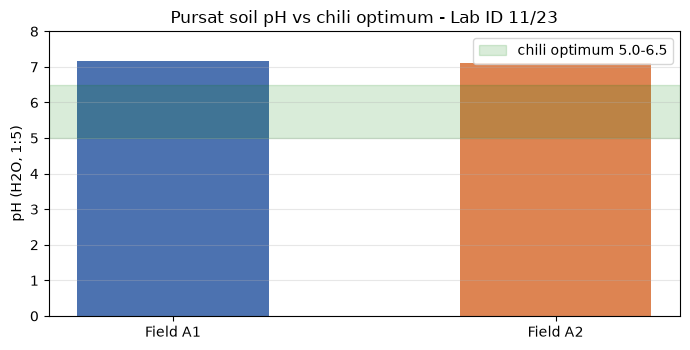

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
vals = [lab.loc[lab["parameter"] == "pH H2O (1:5)", "A1_Field_1"].iloc[0],
        lab.loc[lab["parameter"] == "pH H2O (1:5)", "A2_Field_2"].iloc[0]]
ax.bar(["Field A1", "Field A2"], vals, color=["#4C72B0", "#DD8452"], width=0.5)
ax.axhspan(5.0, 6.5, color="green", alpha=0.15, label="chili optimum 5.0-6.5")
ax.set_ylabel("pH (H2O, 1:5)")
ax.set_ylim(0, 8)
ax.set_title("Pursat soil pH vs chili optimum - Lab ID 11/23")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(BASE, "fig_pursat_soil_ph.png"), dpi=130)
plt.show()

## 9. Kampot vs Pursat — what actually changed

Both runs use identical methods, identical coefficients and the identical 2026 season window. The only thing that differs is the site.

| Metric | Kampot (10.61 N) | Pursat (12.14 N) |
|---|---:|---:|
| Season GDD (base 10) | 2,685.49 | 2,620.58 |
| Mean daily GDD | 17.67 | 17.24 |
| Mean Tmean (C) | 27.37 | 26.84 |
| Max T2M (C) | 31.82 | 35.42 |
| Hours > 35 C (45-150 DAT) | 0.00 | 0.00 |
| Rain total (mm) | 1,401.84 | 900.37 |
| Rainy days | 134.00 | 108.00 |
| Mean RH (%) | 85.47 | 83.68 |
| Hours RH >= 90 % (45-150 DAT) | 878.00 | 1,209.00 |
| GWETROOT mean | 0.85 | 0.70 |
| Est. weather yield loss (%) | 27.86 | 32.18 |
| kg/plant | 1.12 | 1.05 |

**Reading the table:** Pursat is **drier and cooler**, which is good — 500 mm less rain, no heat above 35 °C inside the sensitive window, and a root zone that never saturates for long. But the **harmattan-style humid nights are more frequent**: 1,209 hours at RH ≥ 90 % against 878 at Kampot, which is what pushes the modelled loss from −27.9 % to −32.2 % and the attained yield from 1.12 to **1.05 kg/plant**. The takeaway is clear and slightly counter-intuitive: **for this variety at this location, humidity-driven disease is a bigger constraint than rainfall or heat**.

In [16]:
kc = pd.read_csv(os.path.join(BASE, "Kampot_weather_hourly_2026_season.csv"))
kc["date"] = pd.to_datetime(kc["date"])
kd = pd.read_csv(os.path.join(BASE, "Kampot_GDD_daily_2026.csv"))
kcwin = kc[(kc["DAT"] >= 45) & (kc["DAT"] <= 150)]

comp = pd.DataFrame({
    "metric": ["Season GDD (base 10)", "Mean daily GDD", "Mean Tmean (C)", "Max T2M (C)",
               "Hours > 35 C (45-150 DAT)", "Rain total (mm)", "Rainy days",
               "Mean RH (%)", "Hours RH >= 90 % (45-150 DAT)", "GWETROOT mean",
               "Weather yield loss (%)", "kg/plant"],
    "Kampot": [kd["GDD_cum"].iloc[-1], kd["GDD_day"].mean(), kc["T2M_C"].mean(),
               kc["T2M_C"].max(), int((kcwin["T2M_C"] > 35).sum()),
               kc["PRECTOTCORR_mm"].sum(),
               int((kc.groupby("date")["PRECTOTCORR_mm"].sum() > 1).sum()),
               kc["RH2M_pct"].mean(), int((kcwin["RH2M_pct"] >= 90).sum()),
               kc["GWETROOT_frac"].mean(), 27.86, 1.118],
    "Pursat": [daily["GDD_cum"].iloc[-1], daily["GDD_day"].mean(), df["T2M_C"].mean(),
               df["T2M_C"].max(), h35, df["PRECTOTCORR_mm"].sum(),
               int((df.groupby("date")["PRECTOTCORR_mm"].sum() > 1).sum()),
               df["RH2M_pct"].mean(), rh90, df["GWETROOT_frac"].mean(),
               loss, achieved]}).round(2)
comp

,metric,Kampot,Pursat
0,Season GDD (base 10),2685.49,2620.58
1,Mean daily GDD,17.67,17.24
2,Mean Tmean (C),27.37,26.84
3,Max T2M (C),31.82,35.42
4,Hours > 35 C (45-150 DAT),0.00,0.00
5,Rain total (mm),1401.84,900.37
6,Rainy days,134.00,108.00
7,Mean RH (%),85.47,83.68
8,Hours RH >= 90 % (45-150 DAT),878.00,1209.00
9,GWETROOT mean,0.85,0.70


## 10. Figures

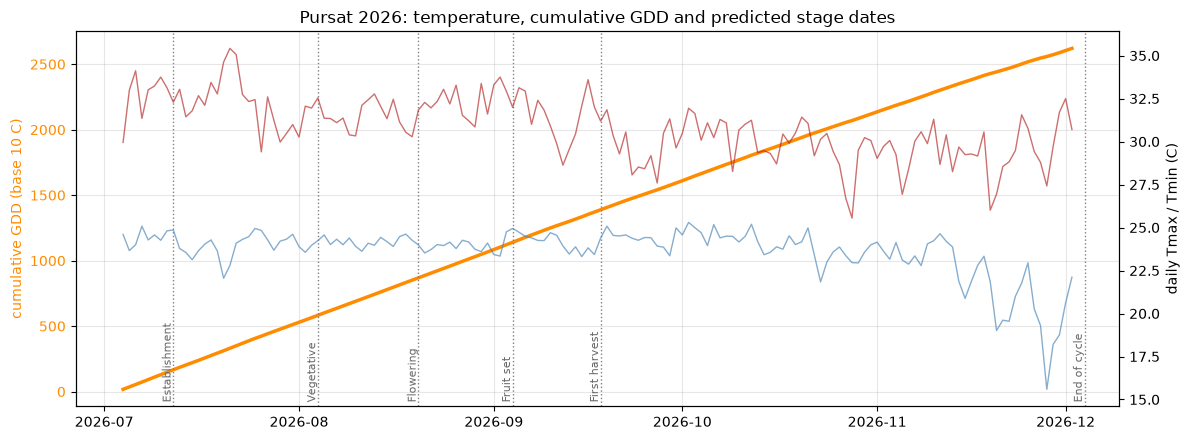

In [17]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily["date"], daily["GDD_cum"], color="darkorange", lw=2.5)
ax.set_ylabel("cumulative GDD (base 10 C)", color="darkorange")
ax.tick_params(axis="y", labelcolor="darkorange")
ax2 = ax.twinx()
ax2.plot(daily["date"], daily["Tmax_C"], color="firebrick", lw=1, alpha=0.65)
ax2.plot(daily["date"], daily["Tmin_C"], color="steelblue", lw=1, alpha=0.65)
ax2.set_ylabel("daily Tmax / Tmin (C)")
for name, p in pred.items():
    ax.axvline(p["date"], color="gray", ls=":", lw=1)
    ax.text(p["date"], ax.get_ylim()[0], " " + name, rotation=90, fontsize=8,
            va="bottom", ha="right", color="dimgray")
ax.set_title("Pursat 2026: temperature, cumulative GDD and predicted stage dates")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(BASE, "fig_pursat_gdd_timeline.png"), dpi=130)
plt.show()

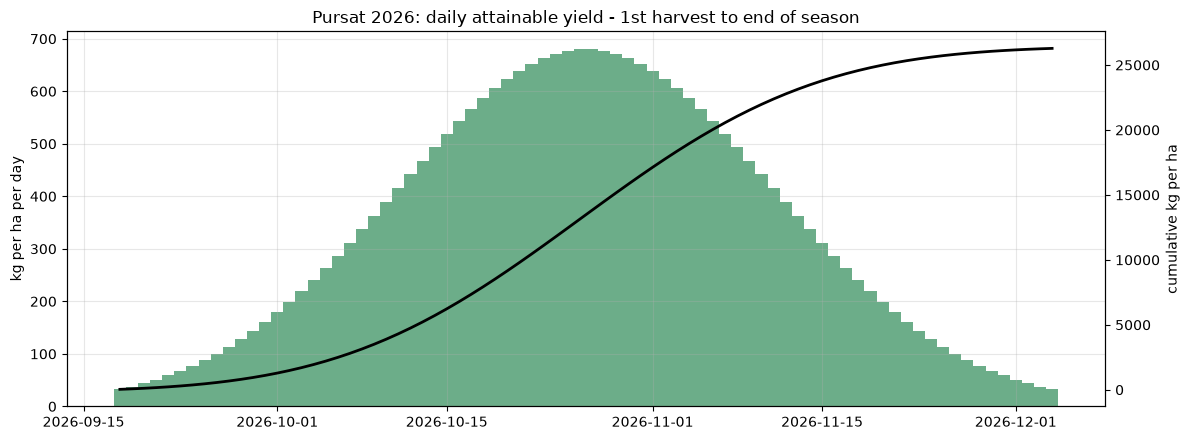

In [18]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(ydf["date"], ydf["kg_per_ha"], width=1.0, color="seagreen", alpha=0.7)
ax.set_ylabel("kg per ha per day")
ax3 = ax.twinx()
ax3.plot(ydf["date"], ydf["kg_per_ha"].cumsum(), color="black", lw=2)
ax3.set_ylabel("cumulative kg per ha")
ax.set_title("Pursat 2026: daily attainable yield - 1st harvest to end of season")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(BASE, "fig_pursat_daily_yield.png"), dpi=130)
plt.show()

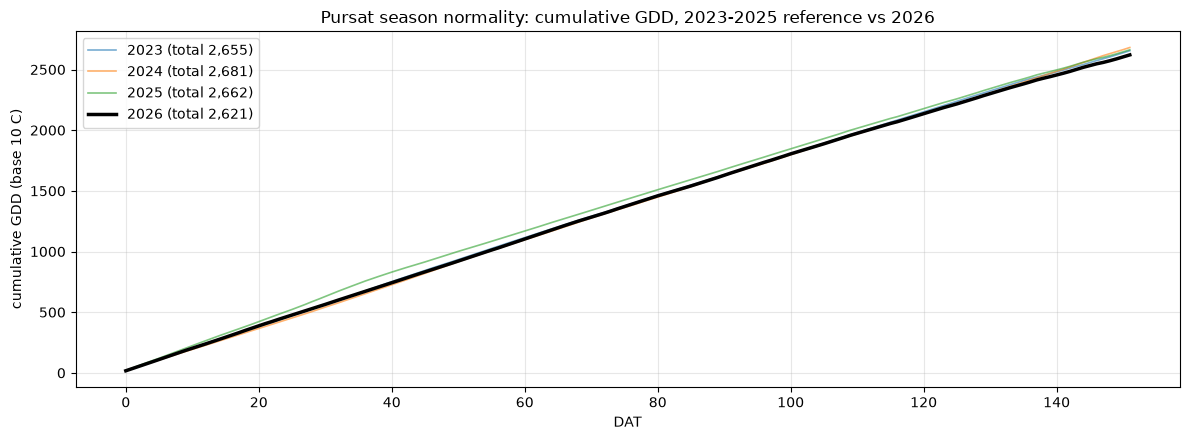

In [19]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for y, g in ref.groupby("year"):
    ax.plot(g["DAT"], g["GDD_cum"], lw=1.2, alpha=0.6,
            label=f"{y} (total {g['GDD_cum'].iloc[-1]:,.0f})")
ax.plot(daily["DAT"], daily["GDD_cum"], color="black", lw=2.5,
        label=f"2026 (total {daily['GDD_cum'].iloc[-1]:,.0f})")
ax.set_xlabel("DAT")
ax.set_ylabel("cumulative GDD (base 10 C)")
ax.set_title("Pursat season normality: cumulative GDD, 2023-2025 reference vs 2026")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(BASE, "fig_pursat_gdd_seasons.png"), dpi=130)
plt.show()

In [20]:
peak = ydf.loc[ydf["kg_per_ha"].idxmax()]
print(f"================ SUMMARY - {SITE} 2026, Red Sky 86 F1 ================")
print(f"Site: lat {LAT}, lon {LON} | elevation {df['elevation_m'].dropna().iloc[0]:.2f} m")
print(f"Season GDD: {daily['GDD_cum'].iloc[-1]:,.0f} | stages +1 to +2 days vs the standard calendar")
print(f"Weather yield loss: -{loss:.1f}% | attained {achieved:.3f} kg/plant | {per_ha_total:,.0f} kg/ha")
print(f"Harvest window: {fh_d} to {eoc_d} | peak {peak['kg_per_ha']:,.0f} kg/ha/day "
      f"on {peak['date'].strftime('%d %b %Y')}")
for name, ha in area_options.items():
    tot = ydf[f"kg_total[{name}]"].sum()
    print(f"Season total ({name} = {ha:.1f} ha): {tot / 1000:,.1f} t "
          f"| {tot / len(ydf):,.0f} kg/day average")

================ SUMMARY - Pursat 2026, Red Sky 86 F1 ================
Site: lat 12.1409, lon 104.0849 | elevation 121.88 m
Season GDD: 2,621 | stages +1 to +2 days vs the standard calendar
Weather yield loss: -32.2% | attained 1.051 kg/plant | 26,280 kg/ha
Harvest window: 18/09/2026 to 04/12/2026 | peak 680 kg/ha/day on 26 Oct 2026
Season total (113 blocks (A1-A66 + B1-B47) = 56.5 ha): 1,484.8 t | 19,036 kg/day average
Season total (69 planted plots = 34.5 ha): 906.7 t | 11,624 kg/day average


## 11. Findings & limitations

**Findings**
- At the instructor's Pursat field, 2026 accumulates **2,621 GDD** (base 10 °C) — **-46 GDD** against the local 2023–2025 mean, a marginally cool season.
- All ten stages therefore arrive **1–2 days later** than the standard DAT calendar; first harvest is predicted for **18/09/2026**, end of cycle around **04/12/2026** (extrapolated 2 days past the window).
- Weather loss is **−32.2 %**, driven almost entirely by **RH ≥ 90 % disease pressure** (1,209 hours), with small contributions from warm nights and 32–35 °C hours. Attained yield **1.05 kg/plant ≈ 26,280 kg/ha**, season total **1,484.8 t** (56.5 ha) or **906.7 t** (34.5 ha).
- Compared with Kampot, Pursat is **cooler and 36 % drier** but has **38 % more high-humidity hours** — the loss is 4.3 points higher despite the drier site.
- The soil report closes the loop: both fields are **silt loam at pH ≈ 7.1**, above the 5.0–6.5 chili optimum, with very high available P (155/173 ppm) and a healthy CEC (~18.5). A2 is the better field (base saturation 78 %, K almost 3× higher).
- The result is robust to the loss coefficients: ±50 % keeps attained yield within **1.01–1.30 kg/plant**.

**Limitations (state these in the report)**
- 13/10/2026 → 02/12/2026 is a **labelled 2025 proxy** (MERRA-2 latency); ≈ 33 % of the modelled loss rests on it.
- The end-of-cycle date is **extrapolated**, because 2026 does not reach the calibrated 2,649 GDD inside the window.
- GDD base temperature fixed at 10 °C; thresholds calibrated on three reference seasons, with **no field-observed stage dates** available to validate them.
- Stress-loss coefficients are **documented assumptions**, not fitted to field data; the farm's spray programme is not modelled.
- NASA POWER grid cell is ~0.5° × 0.625° (**≈ 55 × 69 km**) — one point represents the whole farm, so on-site variation and the real Pursat terrain are not resolved. ERA5-Land (~9 km) is the natural next step.
- The soil lab analysed **two fields (A1, A2)**, not every block; results are assumed representative of the plantation.
- The plantation area is taken from the brief's block/plot inventory (113 blocks or 69 plots); the Pursat farm's actual planted area should be confirmed.
- The five-stage data-collection form's records (DAT, height, yield per harvested block) were **not available** for validation.

**Future data needs** — observed stage dates per block, the farm's spray and fertiliser records, block harvest weights for 2026, the release of the post-12/10/2026 weather, and a finer-resolution reanalysis (ERA5-Land) to test the coarse POWER grid.

## 12. Output files (this folder)

| File | Content |
|---|---|
| `Pursat_weather_hourly_2026_season.csv` | hourly dataset, 3,648 rows, 15 NASA POWER parameters |
| `Pursat_GDD_daily_2026.csv` | daily Tmax/Tmin/Tmean, GDD per day and cumulative |
| `Pursat_reference_GDD_2023-2025.csv` | three reference seasons for threshold calibration |
| `Pursat_stage_predictions.csv` | 10 growth stages: standard vs predicted dates |
| `Pursat_daily_yield.csv` | daily kg/ha plus totals for both area options |
| `Pursat_soil_lab_11-23.csv` | laboratory results for fields A1 and A2 (Lab ID 11/23) |
| `fig_pursat_gdd_timeline.png` · `fig_pursat_daily_yield.png` · `fig_pursat_gdd_seasons.png` · `fig_pursat_soil_ph.png` | report figures |
| `DSS301_Midterm_RedSky86_Pursat.ipynb` / `.html` | this notebook + HTML export with all outputs |